In [ ]:
!pip install ultralytics roboflow opencv-python-headless matplotlib seaborn pandas pillow -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 25.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.8/95.8 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 51.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 45.3 MB/s eta 0:00:00


In [ ]:
import os, shutil, random, yaml, warnings
warnings.filterwarnings("ignore")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from PIL import Image
from pathlib import Path
from IPython.display import display, Image as IPImage
import torch

from ultralytics import YOLO
from roboflow import Roboflow

print("    YOLO Accident Detection — Setup Check")

print(f"PyTorch  : {torch.__version__}")
print(f"CUDA     : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU      : {torch.cuda.get_device_name(0)}")
    print(f"VRAM     : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("⚠️  No GPU detected – switch runtime to GPU for faster training.")

    YOLO Accident Detection — Setup Check
PyTorch  : 2.10.0+cu128
CUDA     : True
GPU      : Tesla T4
VRAM     : 15.6 GB


In [ ]:
# Set ROBOFLOW_API_KEY in Colab secrets or the environment; never hard-code keys.
rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])
project = rf.workspace("accident-detection-ffdrf").project("accident-detection-8dvh5")
dataset  = project.version(1).download("yolov8")

DATASET_DIR = Path(dataset.location)
DATA_YAML   = str(DATASET_DIR / "data.yaml")

print(f"\n Dataset downloaded to: {DATASET_DIR}")

# Quick sanity-check
with open(DATA_YAML) as f:
    cfg = yaml.safe_load(f)
print(f"Classes  : {cfg['names']}")
print(f"Train    : {cfg.get('train','')}")
print(f"Val      : {cfg.get('val','')}")
print(f"Test     : {cfg.get('test','')}")

loading Roboflow workspace...
loading Roboflow project...

 Dataset downloaded to: /content/Accident-Detection-1
Classes  : ['moderate', 'severe']
Train    : ../train/images
Val      : ../valid/images
Test     : ../test/images


In [ ]:
def count_labels(split_path):
    label_dir = Path(split_path).parent / "labels"
    counts = {}
    for lf in label_dir.glob("*.txt"):
        for line in lf.read_text().splitlines():
            cls = int(line.split()[0])
            counts[cls] = counts.get(cls, 0) + 1
    return counts

# Corrected paths
train_img_dir = DATASET_DIR / "train" / "images"
val_img_dir   = DATASET_DIR / "valid" / "images"

train_imgs = list(train_img_dir.glob("*.jpg")) + list(train_img_dir.glob("*.png"))
val_imgs   = list(val_img_dir.glob("*.jpg"))   + list(val_img_dir.glob("*.png"))

train_counts = count_labels(str(train_img_dir))
val_counts   = count_labels(str(val_img_dir))
class_names  = cfg["names"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Dataset Class Distribution", fontsize=16, fontweight="bold")

for ax, counts, split in zip(axes,
                              [train_counts, val_counts],
                              ["Train", "Validation"]):
    labels = [class_names[k] for k in sorted(counts)]
    values = [counts[k] for k in sorted(counts)]
    bars   = ax.bar(labels, values,
                    color=["#e74c3c" if "accident" in l.lower() else "#3498db"
                           for l in labels],
                    edgecolor="white", linewidth=1.5)
    ax.set_title(f"{split} Split ({sum(values)} annotations)", fontsize=13)
    ax.set_ylabel("Annotation Count")
    ax.set_xlabel("Class")
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                str(val), ha="center", va="bottom", fontweight="bold")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

def draw_yolo_boxes(img_path, label_path, class_names):
    img = cv2.imread(str(img_path))
    if img is None:
        return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    colours = {"accident": (231, 76, 60), "non-accident": (52, 152, 219)}
    if label_path.exists():
        for line in label_path.read_text().splitlines():
            parts = line.split()
            cls   = int(parts[0])
            cx, cy, bw, bh = map(float, parts[1:5])
            x1 = int((cx - bw/2) * w);  y1 = int((cy - bh/2) * h)
            x2 = int((cx + bw/2) * w);  y2 = int((cy + bh/2) * h)
            name  = class_names[cls]
            color = colours.get(name, (255, 165, 0))
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
            cv2.putText(img, name, (x1, max(y1-6, 0)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)
    return img

sample_imgs = random.sample(train_imgs, min(8, len(train_imgs)))
fig, axes  = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle("Sample Training Images with Ground-Truth Boxes",
             fontsize=15, fontweight="bold")

for ax, img_path in zip(axes.flat, sample_imgs):
    label_path = img_path.parent.parent / "labels" / (img_path.stem + ".txt")
    rendered   = draw_yolo_boxes(img_path, label_path, class_names)
    if rendered is not None:
        ax.imshow(rendered)
    ax.axis("off")

red_patch  = mpatches.Patch(color=(231/255, 76/255, 60/255),  label="Accident")
blue_patch = mpatches.Patch(color=(52/255, 152/255, 219/255), label="Non-Accident")
fig.legend(handles=[red_patch, blue_patch], loc="lower center",
           ncol=2, fontsize=12, frameon=False)

plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("sample_images.png", dpi=150, bbox_inches="tight")
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
MODEL_SIZE = "yolov8s.pt"   # n=nano | s=small | m=medium | l=large
EPOCHS     = 50
IMG_SIZE   = 640
BATCH      = 16             # reduce to 8 if OOM

model = YOLO(MODEL_SIZE)

print(f"\n Starting training: {MODEL_SIZE}  |  {EPOCHS} epochs  |  img {IMG_SIZE}")
print("─" * 55)

results = model.train(
    data        = DATA_YAML,
    epochs      = EPOCHS,
    imgsz       = IMG_SIZE,
    batch       = BATCH,
    name        = "accident_detection",
    project     = "runs/detect",
    patience    = 15,              # early stopping
    optimizer   = "AdamW",
    lr0         = 1e-3,
    lrf         = 0.01,
    momentum    = 0.937,
    weight_decay= 5e-4,
    warmup_epochs=3,
    hsv_h       = 0.015,
    hsv_s       = 0.7,
    hsv_v       = 0.4,
    flipud      = 0.0,
    fliplr      = 0.5,
    mosaic      = 1.0,
    mixup       = 0.1,
    degrees     = 5.0,
    translate   = 0.1,
    scale       = 0.5,
    shear       = 2.0,
    perspective = 0.0005,
    copy_paste  = 0.1,
    device      = 0 if torch.cuda.is_available() else "cpu",
    verbose     = True,
    plots       = True,
    save        = True,
)
BEST_WEIGHTS = "runs/detect/accident_detection/weights/best.pt"
print(f"\n Training complete. Best weights → {BEST_WEIGHTS}")


 Starting training: yolov8s.pt  |  50 epochs  |  img 640
───────────────────────────────────────────────────────
Ultralytics 8.4.24 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Accident-Detection-1/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.

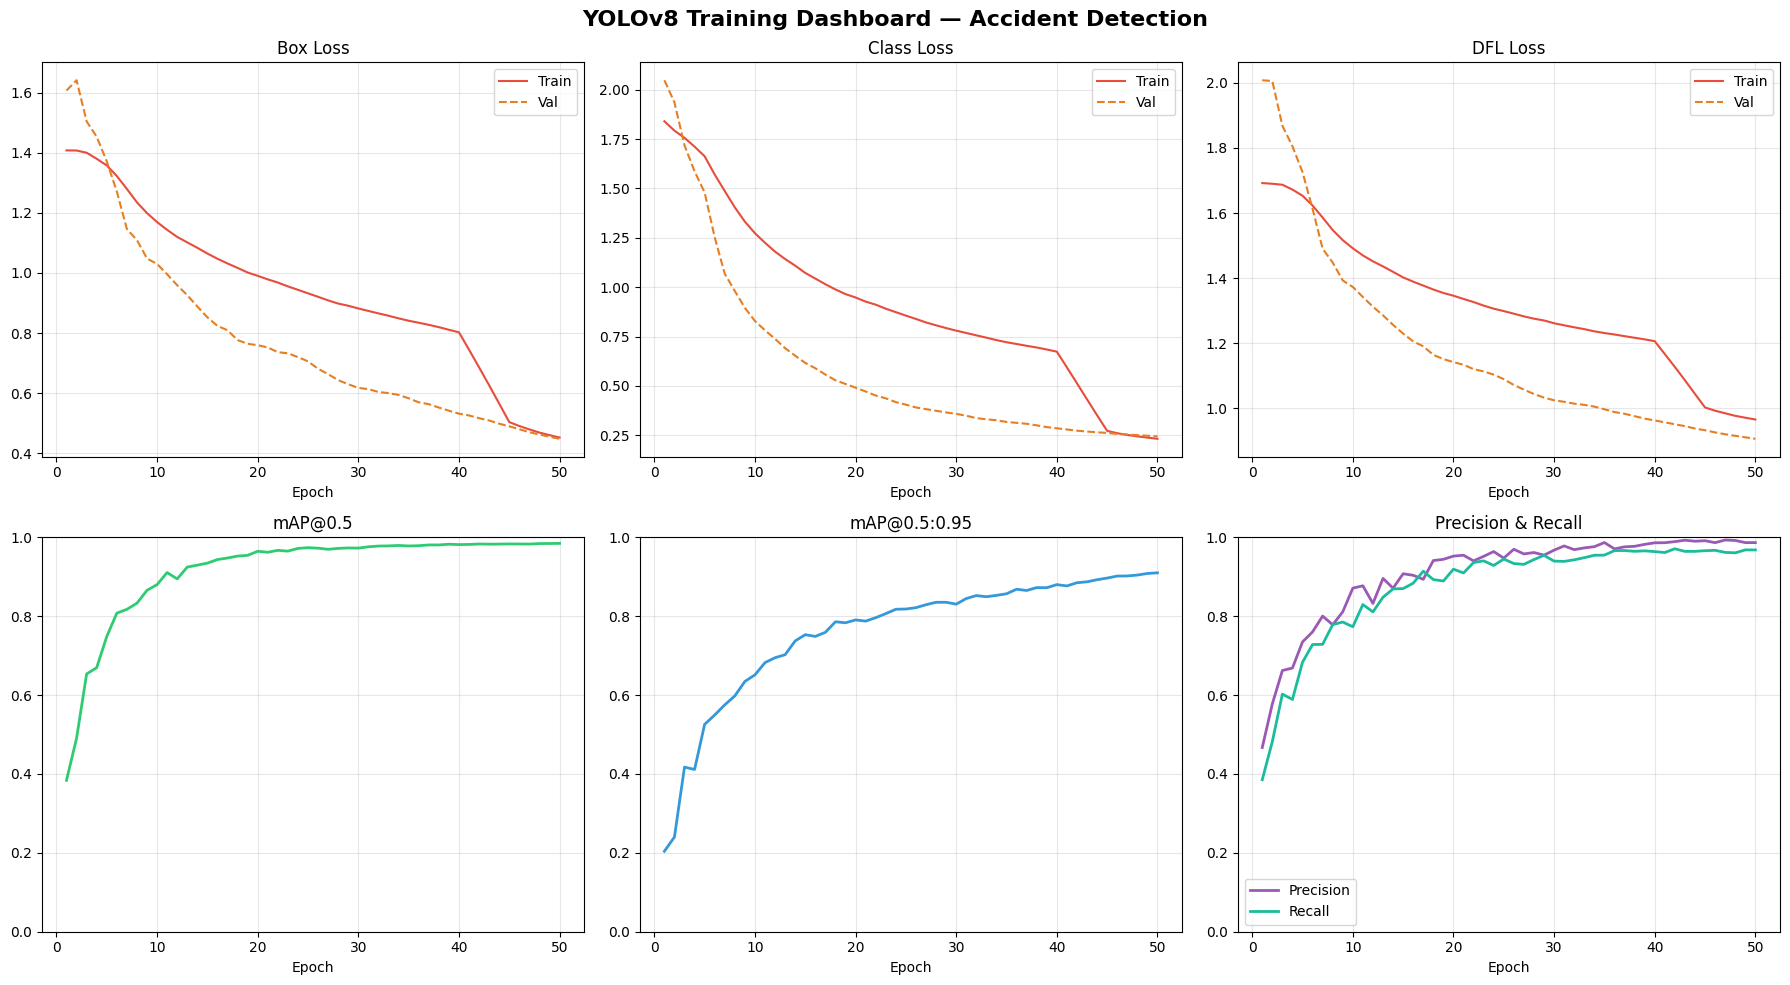


 Best mAP@50     : 0.9847
 Best mAP@50:95  : 0.9101


In [ ]:
results_save_dir = Path(results.save_dir)
csv_path = results_save_dir / "results.csv"
df = pd.read_csv(csv_path)
df.columns = [c.strip() for c in df.columns]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("YOLOv8 Training Dashboard — Accident Detection",
             fontsize=16, fontweight="bold")

LOSS_COLOR   = "#e74c3c"
METRIC_COLOR = "#2ecc71"
VAL_COLOR    = "#e67e22"

def smooth(y, w=5):
    return pd.Series(y).rolling(w, min_periods=1).mean()

epoch = df["epoch"]

# Box loss
axes[0,0].plot(epoch, smooth(df["train/box_loss"]),
               color=LOSS_COLOR, label="Train")
axes[0,0].plot(epoch, smooth(df["val/box_loss"]),
               color=VAL_COLOR, linestyle="--", label="Val")
axes[0,0].set_title("Box Loss"); axes[0,0].set_xlabel("Epoch")
axes[0,0].legend(); axes[0,0].grid(alpha=0.3)

# Class loss
axes[0,1].plot(epoch, smooth(df["train/cls_loss"]),
               color=LOSS_COLOR, label="Train")
axes[0,1].plot(epoch, smooth(df["val/cls_loss"]),
               color=VAL_COLOR, linestyle="--", label="Val")
axes[0,1].set_title("Class Loss"); axes[0,1].set_xlabel("Epoch")
axes[0,1].legend(); axes[0,1].grid(alpha=0.3)

# DFL loss
if "train/dfl_loss" in df.columns:
    axes[0,2].plot(epoch, smooth(df["train/dfl_loss"]),
                   color=LOSS_COLOR, label="Train")
    axes[0,2].plot(epoch, smooth(df["val/dfl_loss"]),
                   color=VAL_COLOR, linestyle="--", label="Val")
    axes[0,2].set_title("DFL Loss"); axes[0,2].set_xlabel("Epoch")
    axes[0,2].legend(); axes[0,2].grid(alpha=0.3)

# mAP@50
axes[1,0].plot(epoch, df["metrics/mAP50(B)"],
               color=METRIC_COLOR, linewidth=2)
axes[1,0].set_title("mAP@0.5"); axes[1,0].set_xlabel("Epoch")
axes[1,0].set_ylim(0, 1); axes[1,0].grid(alpha=0.3)

# mAP@50-95
axes[1,1].plot(epoch, df["metrics/mAP50-95(B)"],
               color="#3498db", linewidth=2)
axes[1,1].set_title("mAP@0.5:0.95"); axes[1,1].set_xlabel("Epoch")
axes[1,1].set_ylim(0, 1); axes[1,1].grid(alpha=0.3)

# Precision & Recall
axes[1,2].plot(epoch, df["metrics/precision(B)"],
               color="#9b59b6", linewidth=2, label="Precision")
axes[1,2].plot(epoch, df["metrics/recall(B)"],
               color="#1abc9c", linewidth=2, label="Recall")
axes[1,2].set_title("Precision & Recall"); axes[1,2].set_xlabel("Epoch")
axes[1,2].set_ylim(0, 1); axes[1,2].legend()
axes[1,2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

best_map50 = df["metrics/mAP50(B)"].max()
best_map95 = df["metrics/mAP50-95(B)"].max()
print(f"\n Best mAP@50     : {best_map50:.4f}")
print(f" Best mAP@50:95  : {best_map95:.4f}")

In [ ]:
BEST_WEIGHTS_ACTUAL = Path(results.save_dir) / "weights" / "best.pt"
best_model = YOLO(BEST_WEIGHTS_ACTUAL)
val_results = best_model.val(
    data   = DATA_YAML,
    imgsz  = IMG_SIZE,
    batch  = BATCH,
    conf   = 0.25,
    iou    = 0.45,
    device = 0 if torch.cuda.is_available() else "cpu",
    plots  = True,
    save_json = True,
)
print("  VALIDATION RESULTS")
print(f"  mAP@50      : {val_results.box.map50:.4f}")
print(f"  mAP@50:95   : {val_results.box.map:.4f}")
print(f"  Precision   : {val_results.box.mp:.4f}")
print(f"  Recall      : {val_results.box.mr:.4f}")

Ultralytics 8.4.24 🚀 Python-3.12.12 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 11,126,358 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2432.0±302.0 MB/s, size: 112.0 KB)
val: Scanning /content/Accident-Detection-1/valid/labels.cache... 1347 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1347/1347 513.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 85/85 4.4it/s 19.1s
                   all       1347       1406      0.984      0.973      0.986      0.916
              moderate        327        329      0.969      0.957      0.977        0.9
                severe       1024       1077      0.998      0.989      0.994      0.932
Speed: 1.2ms preprocess, 8.7ms inference, 0.0ms loss, 0.8ms postprocess per image
Saving /content/runs/detect/val/predictions.json...
Results saved to /content/runs/detect/val
  VALIDATION RESULTS
  mAP@50 

In [ ]:
cm_path = Path("runs/detect/accident_detection/confusion_matrix_normalized.png")
if cm_path.exists():
    img = Image.open(cm_path)
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.imshow(np.array(img))
    ax.set_title("Confusion Matrix (Normalised)", fontsize=14, fontweight="bold")
    ax.axis("off")
    plt.tight_layout()
    plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()

In [ ]:
pr_path = Path("runs/detect/accident_detection/PR_curve.png")
if pr_path.exists():
    img = Image.open(pr_path)
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.imshow(np.array(img))
    ax.set_title("Precision-Recall Curve", fontsize=14, fontweight="bold")
    ax.axis("off")
    plt.tight_layout()
    plt.savefig("pr_curve.png", dpi=150, bbox_inches="tight")
    plt.show()

In [ ]:
test_img_dir = Path(cfg.get("test", str(val_img_dir)))
test_imgs    = (list(test_img_dir.glob("*.jpg")) +
                list(test_img_dir.glob("*.png")))[:12]

if not test_imgs:
    test_imgs = val_imgs[:12]

preds = best_model.predict(
    source  = [str(p) for p in test_imgs],
    conf    = 0.35,
    iou     = 0.45,
    imgsz   = IMG_SIZE,
    device  = 0 if torch.cuda.is_available() else "cpu",
    verbose = False,
)

# Build prediction grid
n     = len(preds)
ncols = 4
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(20, 5 * nrows))
fig.suptitle("Inference Results — Accident Detection", fontsize=16, fontweight="bold")

for idx, (ax, result) in enumerate(zip(axes.flat, preds)):
    rendered = result.plot(font_size=10, pil=True)
    ax.imshow(np.array(rendered))

    # Title with detection summary
    boxes  = result.boxes
    n_det  = len(boxes) if boxes is not None else 0
    labels = []
    if boxes is not None and len(boxes):
        for cls_id in boxes.cls.cpu().numpy().astype(int):
            labels.append(class_names[cls_id])
        label_str = ", ".join(set(labels))
    else:
        label_str = "No detection"

    color  = "#e74c3c" if "accident" in label_str.lower() else "#27ae60"
    ax.set_title(f"Img {idx+1} | {n_det} det | {label_str}",
                 fontsize=9, color=color, fontweight="bold")
    ax.axis("off")

# Hide any leftover axes
for ax in axes.flat[n:]:
    ax.axis("off")

plt.tight_layout()
plt.savefig("inference_results.png", dpi=150, bbox_inches="tight")
plt.show()

Output hidden; open in https://colab.research.google.com to view.

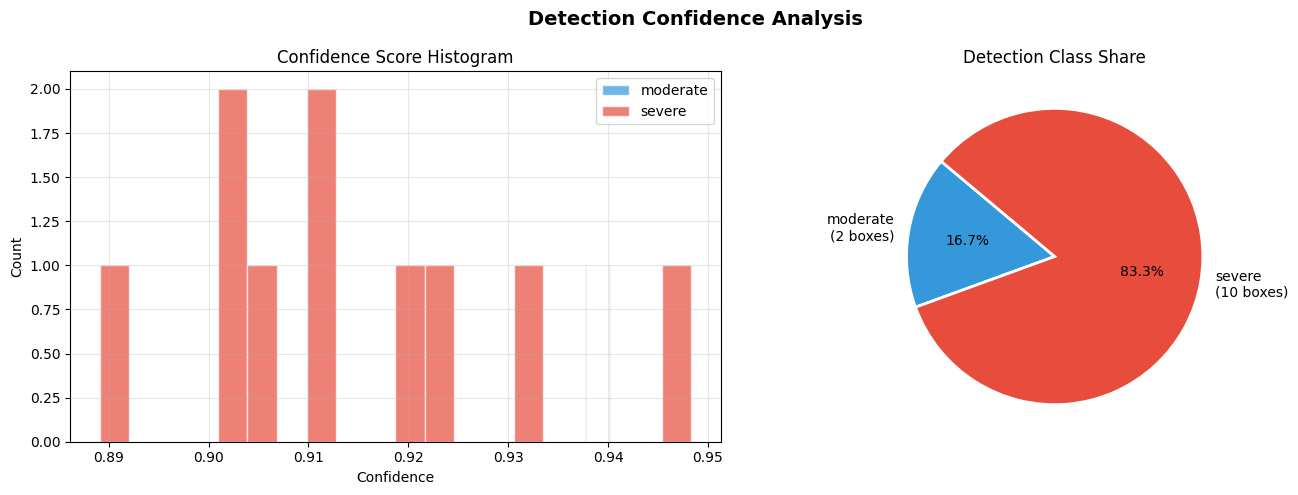

In [ ]:
all_confs   = {name: [] for name in class_names}
all_cls_ids = []

for result in preds:
    if result.boxes is not None and len(result.boxes):
        for cls_id, conf in zip(result.boxes.cls.cpu().numpy().astype(int),
                                 result.boxes.conf.cpu().numpy()):
            name = class_names[cls_id]
            all_confs[name].append(float(conf))
            all_cls_ids.append(name)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Detection Confidence Analysis", fontsize=14, fontweight="bold")

# Histogram
# Assign colors based on actual class names from class_names
color_map = {"moderate": "#3498db", "severe": "#e74c3c"}
for name in class_names:
    vals = all_confs.get(name, [])
    if vals:
        color = color_map.get(name.lower(), "gray") # Default to gray if no specific color
        axes[0].hist(vals, bins=20, alpha=0.7, color=color, label=name, edgecolor="white")
axes[0].set_title("Confidence Score Histogram")
axes[0].set_xlabel("Confidence"); axes[0].set_ylabel("Count")
axes[0].legend(); axes[0].grid(alpha=0.3)

# Pie of detections
det_counts = {k: len(v) for k, v in all_confs.items() if v}
if det_counts:
    labels = [f"{k}\n({v} boxes)" for k, v in det_counts.items()]
    colors = [color_map.get(k.lower(), "gray") for k in det_counts.keys()]
    axes[1].pie(
        det_counts.values(),
        labels=labels,
        colors=colors,
        autopct="%1.1f%%", startangle=140,
        wedgeprops={"edgecolor": "white", "linewidth": 2}
    )
    axes[1].set_title("Detection Class Share")

plt.tight_layout()
plt.savefig("confidence_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

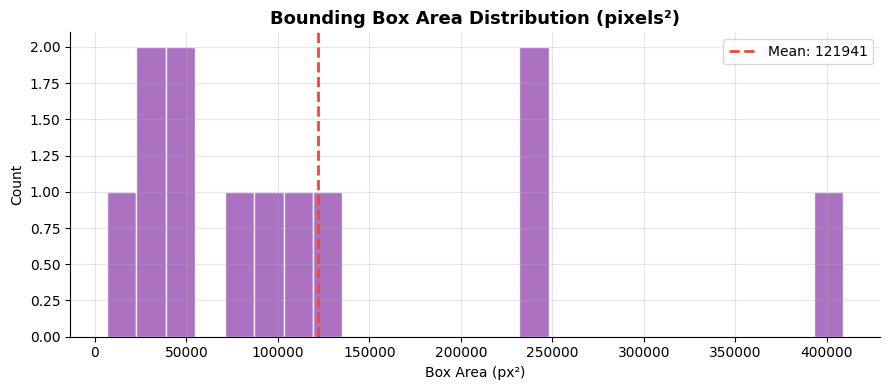

In [ ]:
areas = []
for result in preds:
    if result.boxes is not None and len(result.boxes):
        xyxy = result.boxes.xyxy.cpu().numpy()
        for box in xyxy:
            w = box[2] - box[0]
            h = box[3] - box[1]
            areas.append(w * h)

if areas:
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.hist(areas, bins=25, color="#9b59b6", edgecolor="white", alpha=0.85)
    ax.set_title("Bounding Box Area Distribution (pixels²)",
                 fontsize=13, fontweight="bold")
    ax.set_xlabel("Box Area (px²)"); ax.set_ylabel("Count")
    ax.axvline(np.mean(areas), color="#e74c3c", linestyle="--",
               linewidth=2, label=f"Mean: {np.mean(areas):.0f}")
    ax.legend(); ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.savefig("bbox_area_dist.png", dpi=150, bbox_inches="tight")
    plt.show()

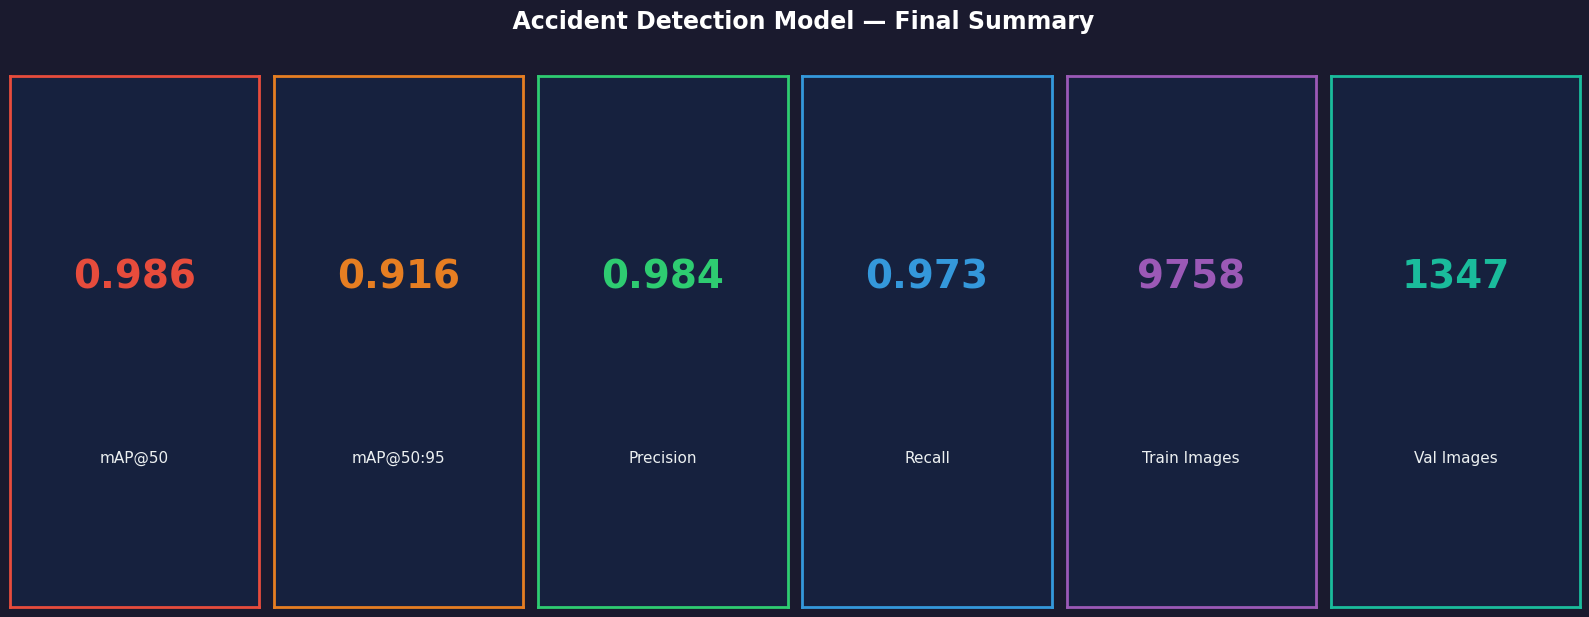

In [ ]:
fig = plt.figure(figsize=(16, 6))
fig.patch.set_facecolor("#1a1a2e")

stats = [
    ("mAP@50",          f"{val_results.box.map50:.3f}", "#e74c3c"),
    ("mAP@50:95",       f"{val_results.box.map:.3f}",   "#e67e22"),
    ("Precision",       f"{val_results.box.mp:.3f}",    "#2ecc71"),
    ("Recall",          f"{val_results.box.mr:.3f}",    "#3498db"),
    ("Train Images",    str(len(train_imgs)),            "#9b59b6"),
    ("Val Images",      str(len(val_imgs)),              "#1abc9c"),
]

for i, (label, value, color) in enumerate(stats):
    ax = fig.add_subplot(1, len(stats), i + 1)
    ax.set_facecolor("#16213e")
    ax.text(0.5, 0.62, value, ha="center", va="center",
            fontsize=28, fontweight="bold", color=color,
            transform=ax.transAxes)
    ax.text(0.5, 0.28, label, ha="center", va="center",
            fontsize=11, color="#ecf0f1",
            transform=ax.transAxes)
    for spine in ax.spines.values():
        spine.set_edgecolor(color); spine.set_linewidth(2)
    ax.set_xticks([]); ax.set_yticks([])

fig.suptitle("  Accident Detection Model — Final Summary",
             fontsize=17, fontweight="bold", color="white", y=1.02)
plt.tight_layout()
plt.savefig("summary_dashboard.png", dpi=150, bbox_inches="tight",
            facecolor=fig.get_facecolor())
plt.show()

In [ ]:
print("\n Exporting best model to ONNX …")
best_model.export(format="onnx", imgsz=IMG_SIZE, simplify=True)
print("  ONNX model saved alongside best.pt")


 Exporting best model to ONNX …
Ultralytics 8.4.24 🚀 Python-3.12.12 torch-2.10.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/

PyTorch: starting from '/content/runs/detect/runs/detect/accident_detection/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 6, 8400) (21.5 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxslim>=0.1.71', 'onnxruntime-gpu'] not found, attempting AutoUpdate...
Using Python 3.12.12 environment at: /usr
Resolved 12 packages in 229ms
Prepared 4 packages in 6.87s
Installed 4 packages in 265ms
 + colorama==0.4.6
 + onnx==1.20.1
 + onnxruntime-gpu==1.24.4
 + onnxslim==0.1.90

requirements: AutoUpdate success ✅ 8.0s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.20.1 opset 20...
ONNX: slimming with onnxslim 0.1.

In [ ]:
print("    All Saved Files")
files = [
    "class_distribution.png",
    "sample_images.png",
    "training_curves.png",
    "confusion_matrix.png",
    "pr_curve.png",
    "inference_results.png",
    "confidence_distribution.png",
    "bbox_area_dist.png",
    "summary_dashboard.png",
    BEST_WEIGHTS,
]
for f in files:
    exists = "" if os.path.exists(f) else ""
    print(f"  {exists}  {f}")
print("\n Done!  Download 'best.pt' from the Files panel on the left.")

    All Saved Files
    class_distribution.png
    sample_images.png
    training_curves.png
    confusion_matrix.png
    pr_curve.png
    inference_results.png
    confidence_distribution.png
    bbox_area_dist.png
    summary_dashboard.png
    runs/detect/accident_detection/weights/best.pt

 Done!  Download 'best.pt' from the Files panel on the left.
